# 04 · Spatial organization of regenerating neurons

By 7 dpa the wound has more neurons than the rest of the body (`03_celltype_dynamics.ipynb`). This notebook asks how the wound is refilled, using the spatial arrangement of neurons and neoblasts within each section.

**Three possible mechanisms.** Each predicts a different spatial pattern at 7 dpa:

| Mechanism | Clustering of neurons vs 0 hpa | Neuron–neoblast spatial relationship | Neuron–neoblast correlation across spots |
|-----------|-------------------------------|--------------------------------------|------------------------------------------|
| **Local burst.** Wound neoblasts produce many neurons in a short time, and the neurons sort into a dense cluster. | higher | strongly negative (the two cell types separate) | strongly negative |
| **Division of surviving neurons.** Neurons left at the wound divide and refill the area without neoblasts. | same or lower | similar to 0 hpa | similar to 0 hpa |
| **Scattered differentiation.** Single neoblasts across the wound turn into neurons independently. | lower (diffuse) | near zero | weak |

**Steps**

1. Correlation between neoblasts and neurons across spots
2. Spatial clustering (Moran's I)
3. Uncertainty of the clustering difference between 0 hpa and 7 dpa
4. Which mechanism fits

**Input:** `data/Scanpy_Visium/Visium_*.h5ad` and `data/processed/02_wound_regions.csv`.

## Setup

Load the same section per timepoint as in `02_wound_region_neoblasts.ipynb`, together with the wound labels saved there. Shared loading code is in `notebooks/common.py`.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import stats

from common import (CELL_TYPES, HOURS, TICK_LBL, TP_ORDER, cell_props,
                    load_blast, load_sections)

sc.settings.verbosity = 0
FIG_DIR = '../figures'
os.makedirs(FIG_DIR, exist_ok=True)

sections = load_sections()
for tp, sec in sections.items():
    print(f"{tp}: {sec.n_obs} spots, {sec.obs['wound_proximal'].sum()} wound-proximal")

props = {tp: cell_props(sec) for tp, sec in sections.items()}

0hpa: 977 spots, 265 wound-proximal
6hpa: 870 spots, 108 wound-proximal
12hpa: 1115 spots, 313 wound-proximal
1dpa: 901 spots, 128 wound-proximal
3dpa: 1231 spots, 367 wound-proximal
7dpa: 1176 spots, 337 wound-proximal


## 1. Correlation between neoblasts and neurons across spots

**What.** In each section, compute the Spearman correlation between the neoblast and neuronal proportions of each spot, and plot the two against each other with wound spots highlighted.

**Why.** A negative correlation means spots rich in neoblasts tend to be poor in neurons, so the two cell types occupy different parts of the tissue. Its strength over time shows when the two are most separated.

**Test.** Spearman rather than Pearson, because proportions are bounded and skewed, and the relationship need not be linear.

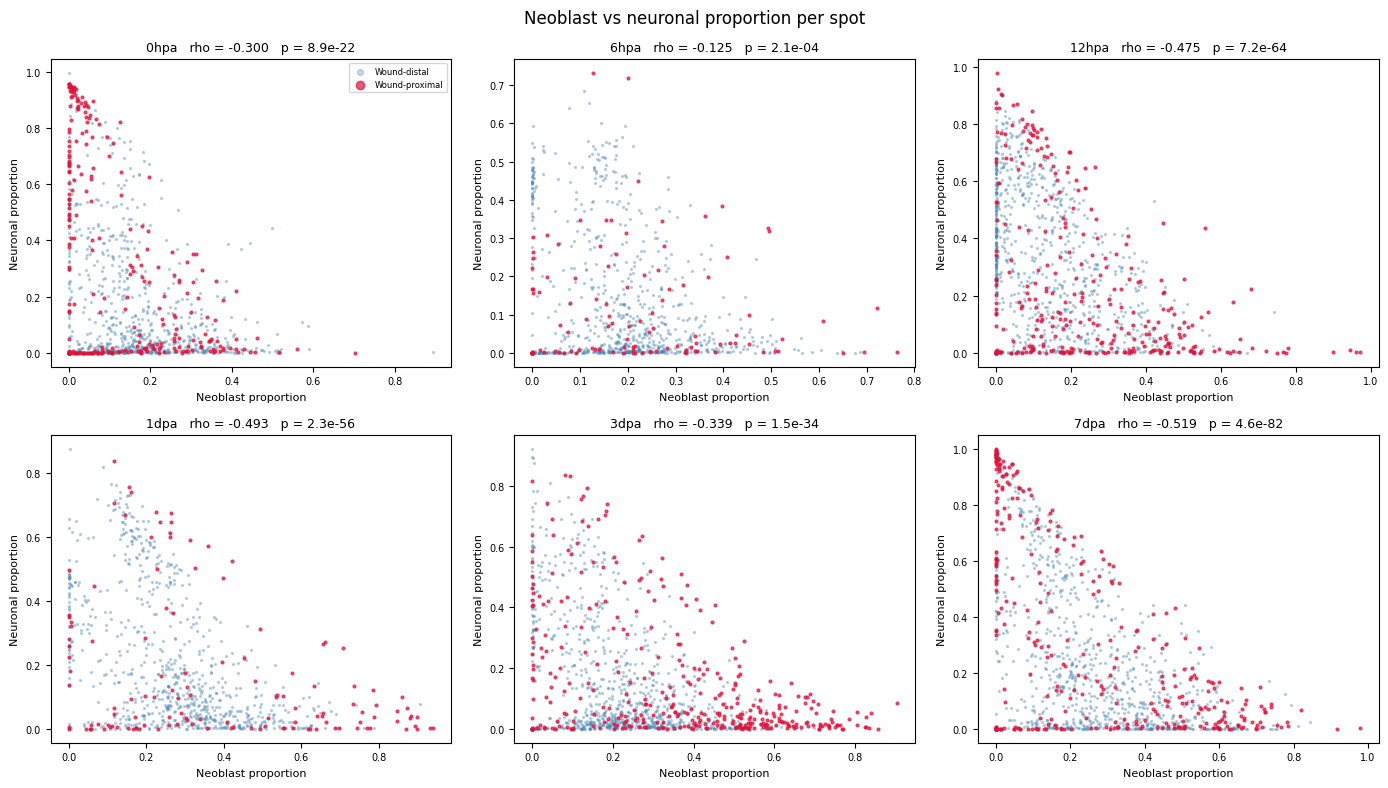

Spearman correlation (neoblast vs neuronal):
timepoint    rho      p_value
     0hpa -0.300 8.937696e-22
     6hpa -0.125 2.137702e-04
    12hpa -0.475 7.213510e-64
     1dpa -0.493 2.280709e-56
     3dpa -0.339 1.510308e-34
     7dpa -0.519 4.577716e-82


In [2]:
corr_records = []
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, tp in zip(axes.flatten(), TP_ORDER):
    neo = props[tp]['Neoblast'].values
    neur = props[tp]['Neuronal'].values
    mask = sections[tp].obs['wound_proximal'].values

    rho, pval = stats.spearmanr(neo, neur)
    corr_records.append({'timepoint': tp, 'rho': round(rho, 3), 'p_value': pval})

    ax.scatter(neo[~mask], neur[~mask], c='steelblue', s=2, alpha=0.3, label='Wound-distal')
    ax.scatter(neo[mask], neur[mask], c='crimson', s=4, alpha=0.7, label='Wound-proximal')
    ax.set_title(f'{tp}   rho = {rho:.3f}   p = {pval:.1e}', fontsize=9)
    ax.set_xlabel('Neoblast proportion', fontsize=8)
    ax.set_ylabel('Neuronal proportion', fontsize=8)
    ax.tick_params(labelsize=7)
    if tp == '0hpa':
        ax.legend(fontsize=6, markerscale=3)

plt.suptitle('Neoblast vs neuronal proportion per spot', fontsize=12)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/04_scatter_by_timepoint.png', dpi=150, bbox_inches='tight')
plt.show()

corr_df = pd.DataFrame(corr_records)
print('Spearman correlation (neoblast vs neuronal):')
print(corr_df.to_string(index=False))

**Result.** Neoblast and neuronal proportions are negatively correlated at every timepoint, so the two cell types tend to occupy different spots. The correlation is weakest at 6 hpa (rho = −0.13), stronger than baseline (−0.30) from 12 hpa to 1 dpa (about −0.48), weaker again at 3 dpa (−0.34), and strongest at 7 dpa (−0.52).

## 2. Spatial clustering (Moran's I)

**What.** Compute three statistics per section on a spatial neighbor graph:
- **Moran's I for neurons** and **for neoblasts**: how strongly each cell type is clustered in space. Values near 0 mean randomly scattered; values near 1 mean neighboring spots have very similar proportions.
- **Bivariate Moran's I** between neoblasts and neurons: whether spots rich in one cell type sit next to spots rich (positive) or poor (negative) in the other.

**Why.** The Spearman correlation in Section 1 ignores where the spots are. A negative correlation could come from two separate tissue regions or from opposite values scattered at random. Moran's I uses spot positions and tells these apart. The clustering of neurons at 7 dpa compared with 0 hpa is the main way to tell the three mechanisms apart.

**Parameters.** Neighbors are the 8 nearest spots, weighted equally (row-normalized), the usual choice for Visium spot grids. Significance of univariate Moran's I comes from 199 random permutations of spot values. Bivariate Moran's I is read together with the other two statistics rather than tested on its own.

Moran's I (neoblast and neuronal proportions):
timepoint  I_neoblast  p_neoblast  I_neuronal  p_neuronal  I_bivariate
     0hpa       0.267       0.005       0.644       0.005       -0.214
     6hpa       0.334       0.005       0.453       0.005       -0.071
    12hpa       0.407       0.005       0.632       0.005       -0.307
     1dpa       0.332       0.005       0.514       0.005       -0.157
     3dpa       0.466       0.005       0.487       0.005       -0.180
     7dpa       0.449       0.005       0.667       0.005       -0.346


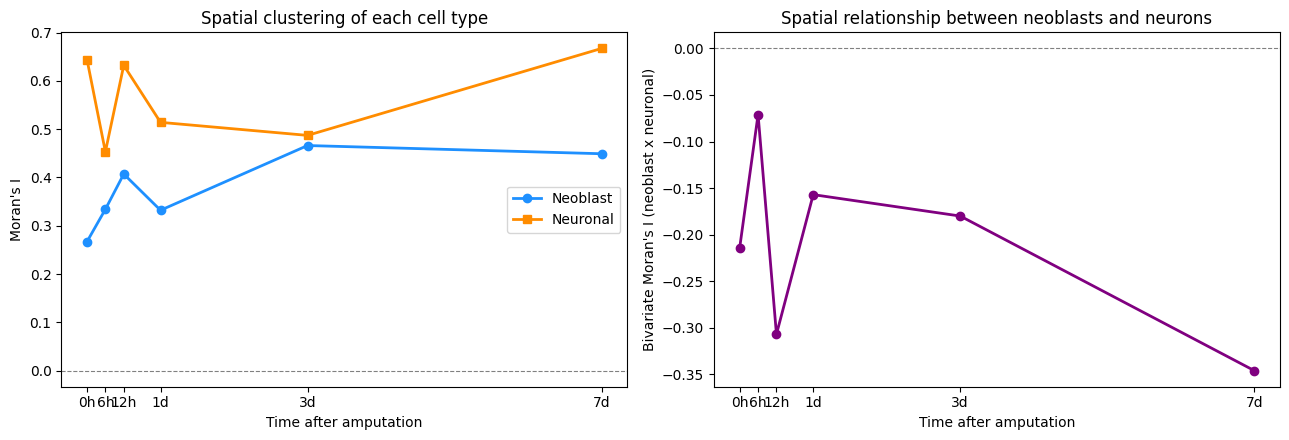

In [3]:
from scipy.sparse import diags, lil_matrix
from sklearn.neighbors import NearestNeighbors


def spatial_weights(coords, k=8):
    # k-nearest-neighbor spatial weights, row-normalized
    n = len(coords)
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(coords).kneighbors(coords)
    W = lil_matrix((n, n))
    for i in range(n):
        for j in idx[i, 1:]:
            W[i, j] = 1.0
    W = W.tocsr()
    rs = np.array(W.sum(axis=1)).flatten()
    rs[rs == 0] = 1
    return diags(1.0 / rs) @ W


def morans_I(x, W):
    x = np.asarray(x, dtype=float)
    xc = x - x.mean()
    return (len(x) / W.sum()) * (xc @ (W @ xc)) / (xc @ xc)


def bivariate_morans_I(x, y, W):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    xc = (x - x.mean()) / (x.std() if x.std() > 0 else 1)
    yc = (y - y.mean()) / (y.std() if y.std() > 0 else 1)
    return (xc @ (W @ yc)) / len(x)


def morans_p(x, W, n_perm=199, seed=0):
    obs = morans_I(x, W)
    rng = np.random.default_rng(seed)
    perm = np.array([morans_I(rng.permutation(x), W) for _ in range(n_perm)])
    return obs, ((np.abs(perm) >= np.abs(obs)).sum() + 1) / (n_perm + 1)


moran_records = []
for tp in TP_ORDER:
    coords = sections[tp].obsm['spatial_scaled']
    neo = props[tp]['Neoblast'].values
    neur = props[tp]['Neuronal'].values
    W = spatial_weights(coords, k=8)
    I_n, p_n = morans_p(neo, W, seed=0)
    I_u, p_u = morans_p(neur, W, seed=1)
    moran_records.append({
        'timepoint': tp,
        'I_neoblast': round(I_n, 3), 'p_neoblast': p_n,
        'I_neuronal': round(I_u, 3), 'p_neuronal': p_u,
        'I_bivariate': round(bivariate_morans_I(neo, neur, W), 3),
    })

moran_df = pd.DataFrame(moran_records)
print("Moran's I (neoblast and neuronal proportions):")
print(moran_df.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(HOURS, moran_df['I_neoblast'], 'o-', color='dodgerblue', linewidth=2, label='Neoblast')
ax[0].plot(HOURS, moran_df['I_neuronal'], 's-', color='darkorange', linewidth=2, label='Neuronal')
ax[0].axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax[0].set_xticks(HOURS); ax[0].set_xticklabels(TICK_LBL)
ax[0].set_xlabel('Time after amputation')
ax[0].set_ylabel("Moran's I")
ax[0].set_title("Spatial clustering of each cell type")
ax[0].legend()

ax[1].plot(HOURS, moran_df['I_bivariate'], 'o-', color='purple', linewidth=2)
ax[1].axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax[1].set_xticks(HOURS); ax[1].set_xticklabels(TICK_LBL)
ax[1].set_xlabel('Time after amputation')
ax[1].set_ylabel("Bivariate Moran's I (neoblast x neuronal)")
ax[1].set_title("Spatial relationship between neoblasts and neurons")
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/04_morans_i.png', dpi=150, bbox_inches='tight')
plt.show()

**Result.** - Neurons are strongly clustered at every timepoint (Moran's I 0.45–0.67; p = 0.005 in all cases, the smallest value possible with 199 permutations). Clustering drops right after cutting (0.45 at 6 hpa) and is highest at 7 dpa (0.667), slightly above 0 hpa (0.644).
- Neoblasts become more clustered over time, from 0.27 at 0 hpa to 0.45–0.47 at 3–7 dpa.
- Bivariate Moran's I is negative at every timepoint: neoblast-rich spots sit next to neuron-poor spots. It is most negative at 7 dpa (−0.35), with 12 hpa close behind (−0.31), and weaker at 1–3 dpa (−0.16 and −0.18), when the wound holds a mixture of both cell types.

## 3. Uncertainty of the clustering difference between 0 hpa and 7 dpa

**What.** Estimate a 95% confidence interval for the neuronal Moran's I at 0 hpa and 7 dpa, and for their difference, using a spatial block bootstrap.

**Why.** The difference between 7 dpa and 0 hpa is small, and with one section per timepoint there is no replicate to judge whether it is real. Resampling within each section gives a sense of how much the value would move with a slightly different set of spots.

**How.**
1. Split the spots of each section into 20 spatial blocks (k-means on coordinates).
2. Draw 20 blocks with replacement and pool their spots.
3. Rebuild the neighbor graph and recompute Moran's I.
4. Repeat 500 times and take the 2.5 and 97.5 percentiles.

Resampling whole blocks instead of single spots keeps neighboring spots together, so the local spatial structure that Moran's I measures is preserved.

Block bootstrap of neuronal Moran's I (500 resamples, 20 blocks)
timepoint   estimate    2.5%   97.5%
0hpa           0.644   0.475   0.819
7dpa           0.667   0.587   0.830

Difference 7 dpa - 0 hpa: mean +0.049, 95% CI [-0.174, +0.277], fraction <= 0: 0.374


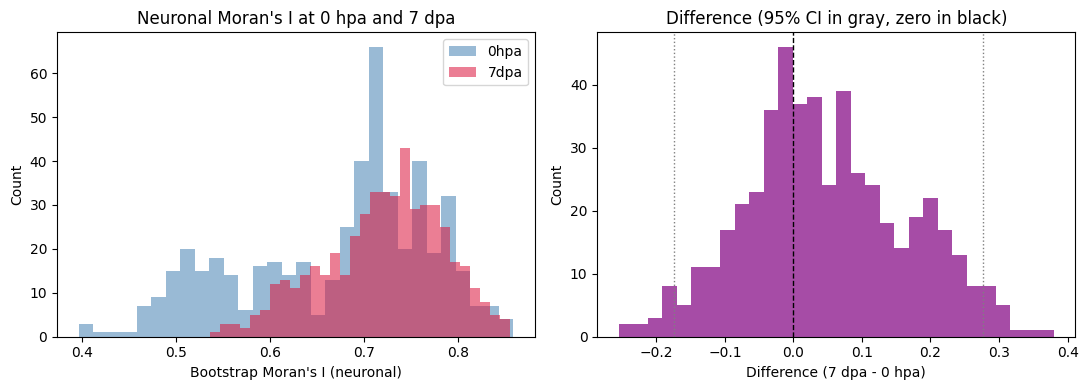

In [4]:
from sklearn.cluster import KMeans


def block_bootstrap_morans_I(coords, values, n_blocks=20, n_boot=500, k=8, seed=0):
    rng = np.random.default_rng(seed)
    labels = KMeans(n_clusters=n_blocks, n_init=4, random_state=seed).fit(coords).labels_
    blocks = [np.where(labels == b)[0] for b in range(n_blocks)]
    blocks = [b for b in blocks if len(b) > 0]
    boot = np.empty(n_boot)
    for r in range(n_boot):
        idx = np.concatenate([blocks[c] for c in rng.integers(0, len(blocks), size=len(blocks))])
        boot[r] = morans_I(values[idx], spatial_weights(coords[idx], k=k))
    return boot


boot = {}
for tp in ['0hpa', '7dpa']:
    coords = np.asarray(sections[tp].obsm['spatial_scaled'])
    boot[tp] = block_bootstrap_morans_I(coords, props[tp]['Neuronal'].values, seed=42)

print("Block bootstrap of neuronal Moran's I (500 resamples, 20 blocks)")
print(f"{'timepoint':<10} {'estimate':>9} {'2.5%':>7} {'97.5%':>7}")
for tp in ['0hpa', '7dpa']:
    est = float(moran_df.loc[moran_df['timepoint'] == tp, 'I_neuronal'].iloc[0])
    lo, hi = np.percentile(boot[tp], [2.5, 97.5])
    print(f'{tp:<10} {est:>9.3f} {lo:>7.3f} {hi:>7.3f}')

diff = boot['7dpa'] - boot['0hpa']
diff_lo, diff_hi = np.percentile(diff, [2.5, 97.5])
print(f"\nDifference 7 dpa - 0 hpa: mean {diff.mean():+.3f}, "
      f"95% CI [{diff_lo:+.3f}, {diff_hi:+.3f}], "
      f"fraction <= 0: {(diff <= 0).mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for tp, color in zip(['0hpa', '7dpa'], ['steelblue', 'crimson']):
    ax[0].hist(boot[tp], bins=30, alpha=0.55, color=color, label=tp)
ax[0].set_xlabel("Bootstrap Moran's I (neuronal)")
ax[0].set_ylabel('Count')
ax[0].set_title("Neuronal Moran's I at 0 hpa and 7 dpa")
ax[0].legend()
ax[1].hist(diff, bins=30, color='purple', alpha=0.7)
ax[1].axvline(0, color='black', linestyle='--', linewidth=1)
for v in (diff_lo, diff_hi):
    ax[1].axvline(v, color='gray', linestyle=':', linewidth=1)
ax[1].set_xlabel('Difference (7 dpa - 0 hpa)')
ax[1].set_ylabel('Count')
ax[1].set_title('Difference (95% CI in gray, zero in black)')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/04_bootstrap.png', dpi=150, bbox_inches='tight')
plt.show()

**Result.** The two confidence intervals overlap widely (0 hpa: 0.48–0.82; 7 dpa: 0.59–0.83). The difference is +0.05 with a 95% CI of −0.17 to +0.28, and in 37% of resamples 7 dpa is not higher than 0 hpa. The higher neuronal clustering at 7 dpa cannot be told apart from the baseline level.

## 4. Which mechanism fits

Observed values at 7 dpa compared with the predictions in the introduction:

| Statistic | 7 dpa (0 hpa) | Local burst | Division of surviving neurons | Scattered differentiation |
|-----------|---------------|-------------|-------------------------------|---------------------------|
| Neuronal Moran's I | 0.667 (0.644), difference within noise | higher, not shown | same or lower ✓ | lower ✗ |
| Bivariate Moran's I | −0.35 (−0.21) | strongly negative ✓ | similar to 0 hpa ✗ | near zero ✗ |
| Spearman rho | −0.52 (−0.30) | strongly negative ✓ | similar to 0 hpa ✗ | weak ✗ |

- **Scattered differentiation** does not fit: neurons are as clustered as at baseline, and they are clearly separated from neoblasts.
- **Division of surviving neurons** fits the clustering level but not the neuron–neoblast relationship, which is clearly stronger than at baseline on both measures.
- **Local burst** fits the neuron–neoblast relationship. Its prediction of higher-than-baseline clustering is not supported, because the bootstrap shows the difference is within noise.

The local burst model is the most consistent with the data. The support comes from the separation between neurons and neoblasts, not from the level of neuronal clustering.

## Summary

- Neurons stay strongly clustered throughout regeneration, and they are spatially separated from neoblasts at every timepoint.
- At 7 dpa the separation between neurons and neoblasts is the strongest of the time course on both the spot-level correlation and bivariate Moran's I.
- Taken together, the data fit best with neurons being produced locally at the wound and sorting into a compact cluster. The bootstrap shows that neuronal clustering at 7 dpa is not measurably higher than baseline, so that statistic alone does not separate the mechanisms.
- With one section per timepoint, these are single measurements. Only the neuronal clustering difference has an uncertainty estimate.

**Next:** `05_neural_maturity.ipynb` asks whether the rebuilt tissue is also molecularly mature.